# **Install required libraries**

In [2]:
%pip install datasets torch torchvision matplotlib pillow pandas scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 4.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 4.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 3.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 3.8 MB/s  0:00:36m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 4.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 3.8 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 4.0 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 3.9 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 3.8 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 4.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 3.9 MB/s  0:00:01 

In [16]:
import sys
import platform

print("Python version:", platform.python_version())
print("Python location:", sys.executable)
print("Architecture:", platform.machine())

Python version: 3.14.6
Python location: /opt/anaconda3/envs/Retinal_OCT_Project/bin/python
Architecture: arm64


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("Apple GPU available:", torch.backends.mps.is_available())

PyTorch version: 2.15.0
Apple GPU available: True


# **Load the OCT dataset from Hugging Face**

In [4]:
from datasets import load_dataset

ds = load_dataset("zacharielegault/Kermany2017-OCT")

print(ds)

/opt/anaconda3/envs/Retinal_OCT_Project/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 1000/1000 [00:00<00:00, 32240.56 examples/s]


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})


In [6]:
print(ds.keys())

dict_keys(['train', 'test'])


# **Access training and testing data**

In [8]:
train_data = ds["train"]
test_data = ds["test"]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print(train_data.features)

Training samples: 108309
Testing samples: 1000
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}


# **Access an individual image**

Label: 0
Image size: (512, 496)
Image mode: L


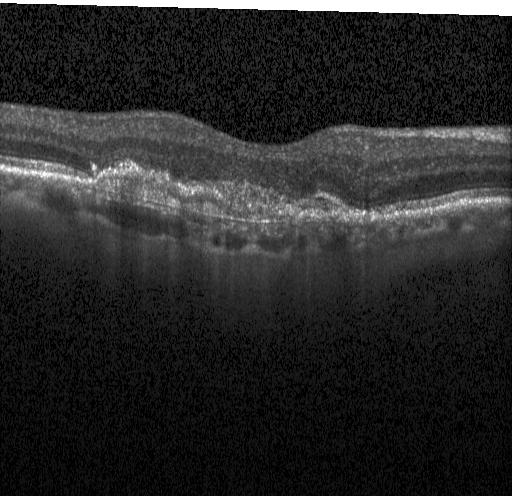

In [7]:
sample = train_data[0]

image = sample["image"]
label = sample["label"]

print("Label:", label)
print("Image size:", image.size)
print("Image mode:", image.mode)

display(image)

# **count the scans in each class**

In [14]:
from collections import Counter

label_names = train_data.features["label"].names
counts = Counter(train_data["label"])

for label_id, name in enumerate(label_names):
    count = counts[label_id]
    percentage = 100 * count / len(train_data)
    print(f"{name}: {count:,} scans ({percentage:.1f}%)")

CNV: 37,205 scans (34.4%)
DME: 11,348 scans (10.5%)
DRUSEN: 8,616 scans (8.0%)
NORMAL: 51,140 scans (47.2%)


# **Visualize multiple images**

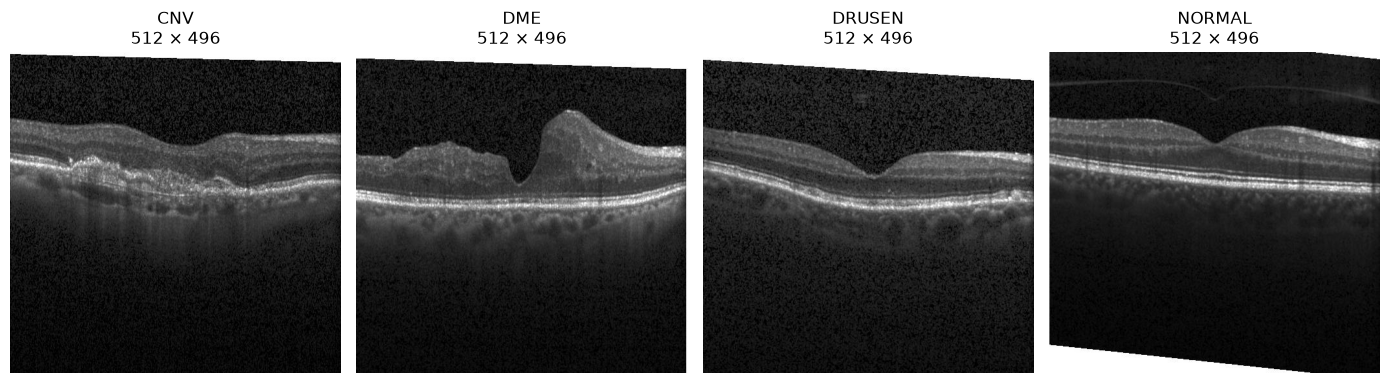

In [15]:
import matplotlib.pyplot as plt

labels = list(train_data["label"])
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for label_id, name in enumerate(label_names):
    row = labels.index(label_id)
    image = train_data[row]["image"]

    axes[label_id].imshow(image, cmap="gray")
    axes[label_id].set_title(f"{name}\n{image.width} × {image.height}")
    axes[label_id].axis("off")

plt.tight_layout()
plt.show()

# **check whether image sizes vary**

In [18]:
import random
from collections import Counter

rows = random.Random(42).sample(range(len(train_data)), 100)
size_counts = Counter()
mode_counts = Counter()

for row in rows:
    image = train_data[row]["image"]
    size_counts[image.size] += 1
    mode_counts[image.mode] += 1

print("Image sizes in 100 scans:", size_counts)
print("Image modes in 100 scans:", mode_counts)

Image sizes in 100 scans: Counter({(512, 496): 60, (768, 496): 24, (1536, 496): 9, (512, 512): 7})
Image modes in 100 scans: Counter({'L': 100})


# **resizing with padding for one image sample**

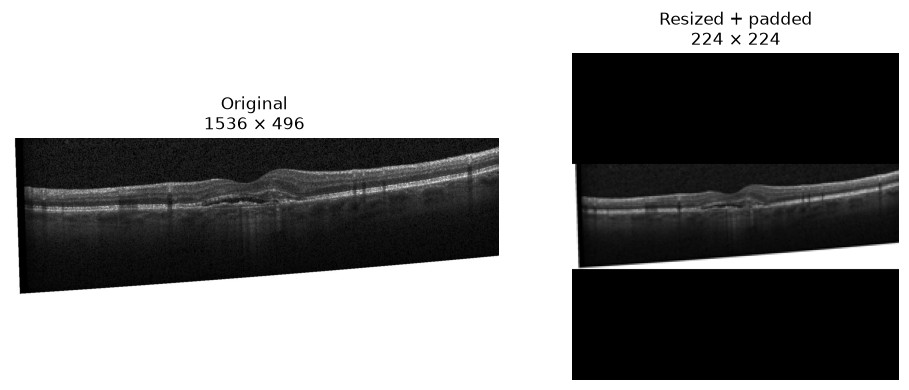

In [19]:
from PIL import ImageOps
import matplotlib.pyplot as plt

for row in rows:
    scan = train_data[row]["image"]
    if scan.size == (1536, 496):
        break

preview = ImageOps.pad(scan, (224, 224), color=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, image, title in zip(axes, [scan, preview], ["Original", "Resized + padded"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{title}\n{image.width} × {image.height}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# **how PyTorch represents the grayscale image as numbers.**

In [21]:
from torchvision.transforms.functional import to_tensor

scan_tensor = to_tensor(preview)

print("Shape:", scan_tensor.shape)
print("Data type:", scan_tensor.dtype)
print("Darkest pixel:", scan_tensor.min().item())
print("Brightest pixel:", scan_tensor.max().item())

Shape: torch.Size([1, 224, 224])
Data type: torch.float32
Darkest pixel: 0.0
Brightest pixel: 1.0


In [22]:
import torch

# Use the first training scan as a second example (originally 512 × 496).
second_scan = train_data[0]["image"]
second_preview = ImageOps.pad(second_scan, (224, 224), color=0)
second_tensor = to_tensor(second_preview)

# Stack this scan with the wide scan you already prepared.
batch = torch.stack([scan_tensor, second_tensor])

print("One scan:", scan_tensor.shape)
print("Batch:", batch.shape)

One scan: torch.Size([1, 224, 224])
Batch: torch.Size([2, 1, 224, 224])


In [23]:
first_label = train_data[row]["label"]
second_label = train_data[0]["label"]

batch_labels = torch.tensor([first_label, second_label])

print("Label IDs:", batch_labels.tolist())
print("Class names:", [label_names[first_label], label_names[second_label]])
print("Label shape:", batch_labels.shape)

Label IDs: [0, 0]
Class names: ['CNV', 'CNV']
Label shape: torch.Size([2])


In [25]:
print("Brightness of the top-left pixel:", batch[0, 0, 0, 0].item())
print("Class name of the first scan:", label_names[batch_labels[0].item()])

Brightness of the top-left pixel: 0.0
Class name of the first scan: CNV
